# 01 · anemoi-datasets: the data layer of Anemoi

**AIWCAS 2026 · Anemoi hands-on, part 1 · about 20 minutes**

Every Anemoi model (training, fine-tuning, inference) reads its data through **anemoi-datasets**.
In this notebook you **open and explore** existing datasets. You don't create any here, because building them from GRIB/NetCDF takes hours and is a job for the data team.

By the end you should be able to explain:

1. **Anatomy.** How an anemoi dataset is laid out on disk (a Zarr store), and *why* it is laid out that way.
2. **Metadata.** What is stored next to the numbers (variables, statistics, the full recipe and provenance), and how to inspect it.
3. **`open_dataset`.** How one function turns a few stored datasets into an unlimited number of *lazy views* (subsets, crops, joins, cutouts) without copying a byte.

| Section | Topic | ≈ min |
|---|---|---|
| 0 | Setup | 1 |
| 1 | Anatomy: the 4-D array, chunks, flat grids, statistics, missing dates | 7 |
| 2 | Metadata: `inspect`, attributes, recipe, provenance | 3 |
| 3 | `open_dataset`: lazy views and how they compose | 8 |
| 4 | Wrap-up | 1 |

There are three short **✏️ Try it** exercises; solutions are folded under *Show solution*.

## 0 · Setup

The data are small public samples from ECMWF's test bucket, prepared by the instructors with `scripts/download_data.sh` (about 560 MB in total).
**If your copy lives elsewhere, edit `DATA_DIR` below**; nothing else in the notebook needs to change.

| Short name | Dataset | Grid | Used for |
|---|---|---|---|
| `O96` | `aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing` | ERA5, reduced Gaussian ≈ 1°, 101 variables, 10 days | most of the notebook |
| `O48` | `aifs-ea-an-oper-0001-mars-o48-1979-19-6h-v6-testset` | ERA5, reduced Gaussian ≈ 2° | cutout (global part) |
| `WB2` | `keisler-era5-gs-weatherbench2-1p0d-1979-1979-3h-v0` | ERA5 from WeatherBench 2, regular 1° lat/lon | thinning, rename, cutout (regional part) |
| `T20_*` | `aifs-ea-…-20p0-…` | toy 20° grids | join / concat / ensemble |

In [1]:
# ┌───────────────────────────────────────────────────────────────────────┐
# │  EDIT ME: where scripts/download_data.sh put the data                 │
DATA_DIR = "/leonardo_work/tra26_aiwcas/a08trd25/data"
# └───────────────────────────────────────────────────────────────────────┘

import logging
import os
import time

import cartopy
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import yaml
import zarr
from scipy.spatial import ConvexHull

from anemoi.datasets import open_dataset

A = f"{DATA_DIR}/anemoi"
O96 = f"{A}/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr"
O48 = f"{A}/aifs-ea-an-oper-0001-mars-o48-1979-19-6h-v6-testset.zarr"
WB2 = f"{A}/keisler-era5-gs-weatherbench2-1p0d-1979-1979-3h-v0.zarr"
T20_SFC = f"{A}/aifs-ea-an-oper-0001-mars-20p0-2017-2017-6h-v1-sfc.zarr"
T20_PL = f"{A}/aifs-ea-an-oper-0001-mars-20p0-2017-2017-6h-v1-pl.zarr"
T20_2016 = f"{A}/aifs-ea-an-oper-0001-mars-20p0-2016-2016-6h-v1.zarr"
T20_2017 = f"{A}/aifs-ea-an-oper-0001-mars-20p0-2017-2017-6h-v1.zarr"
T20_ENS = f"{A}/aifs-ea-an-enda-0001-mars-20p0-2017-2017-6h-v1.zarr"
assert os.path.isdir(O96), f"Dataset not found, check DATA_DIR: {O96}"

cartopy.config["data_dir"] = f"{DATA_DIR}/cartopy"   # pre-downloaded coastlines, works offline
logging.getLogger("anemoi").setLevel(logging.ERROR)  # keep the outputs short

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "grid.linewidth": 0.6,
})
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6", "ink": "#52514e"}


def lon180(lon):
    """Longitudes in [-180, 180): avoids a seam through Europe when triangulating."""
    return (np.asarray(lon) + 180) % 360 - 180


def show_field(ax, lats, lons, values, *, cmap="viridis", label="", vmin=None, vmax=None, colorbar=True):
    """Map values given on *flat* lat/lon arrays: works for any grid, no 2-D reshape needed.

    Triangulates the points on the sphere (3-D convex hull), projects them to the map,
    and colours the triangles (smooth, gap-free, also at the poles).
    """
    lats, lons = np.asarray(lats, float), lon180(lons)
    la, lo = np.radians(lats), np.radians(lons)
    xyz = np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]
    hull = ConvexHull(xyz)
    tris = hull.simplices
    outward = np.einsum("ij,ij->i", hull.equations[:, :3], xyz[tris].mean(axis=1)) > 0  # drop the flat "lid" of regional patches
    pts = ax.projection.transform_points(ccrs.PlateCarree(), lons, lats)[:, :2]
    ok = np.isfinite(pts).all(axis=1)                                   # e.g. far side of an orthographic globe
    pts[~ok] = 0
    wraps = np.ptp(pts[tris, 0], axis=1) > 0.5 * np.ptp(pts[ok, 0])         # triangles torn across the map edge
    keep = outward & ok[tris].all(axis=1) & ~wraps
    im = ax.tripcolor(mtri.Triangulation(pts[:, 0], pts[:, 1], tris[keep]), values,
                      cmap=cmap, vmin=vmin, vmax=vmax, shading="gouraud", rasterized=True)
    ax.coastlines(resolution="50m" if np.ptp(lats) < 90 else "110m", linewidth=0.6, color="#222222")
    if colorbar:
        plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.04, shrink=0.85, aspect=35, label=label)
    return im


print("anemoi-datasets", __import__("anemoi.datasets").datasets.__version__, "| zarr", zarr.__version__)

anemoi-datasets 0.5.47 | zarr 2.18.7


## 1 · Anatomy of an anemoi dataset

### 1.1 It's just a Zarr store

An anemoi dataset is a **Zarr** store: a directory of N-dimensional arrays split into compressed *chunks* (one file each), plus JSON attributes.
Let's look at it with plain `zarr`, without anemoi at all:

In [2]:
z = zarr.open(O96, mode="r")

names = sorted(name for name, _ in z.arrays())
for n in names:
    if not n.startswith("statistics_tendencies"):
        a = z[n]
        print(f"{n:10s} shape={str(a.shape):20s} chunks={str(a.chunks):20s} dtype={a.dtype}")
tend = [n for n in names if n.startswith("statistics_tendencies")]
print(f"\n+ {len(tend)} 'statistics_tendencies_*' arrays, e.g. {', '.join(tend[:3])}, …")

count      shape=(101,)               chunks=(101,)               dtype=int64
data       shape=(39, 101, 1, 40320)  chunks=(1, 101, 1, 40320)   dtype=float32
dates      shape=(39,)                chunks=(39,)                dtype=datetime64[s]
has_nans   shape=(101,)               chunks=(101,)               dtype=bool
latitudes  shape=(40320,)             chunks=(20160,)             dtype=float64
longitudes shape=(40320,)             chunks=(20160,)             dtype=float64
maximum    shape=(101,)               chunks=(101,)               dtype=float64
mean       shape=(101,)               chunks=(101,)               dtype=float64
minimum    shape=(101,)               chunks=(101,)               dtype=float64
squares    shape=(101,)               chunks=(101,)               dtype=float64
stdev      shape=(101,)               chunks=(101,)               dtype=float64
sums       shape=(101,)               chunks=(101,)               dtype=float64

+ 24 'statistics_tendencies_*' arrays,

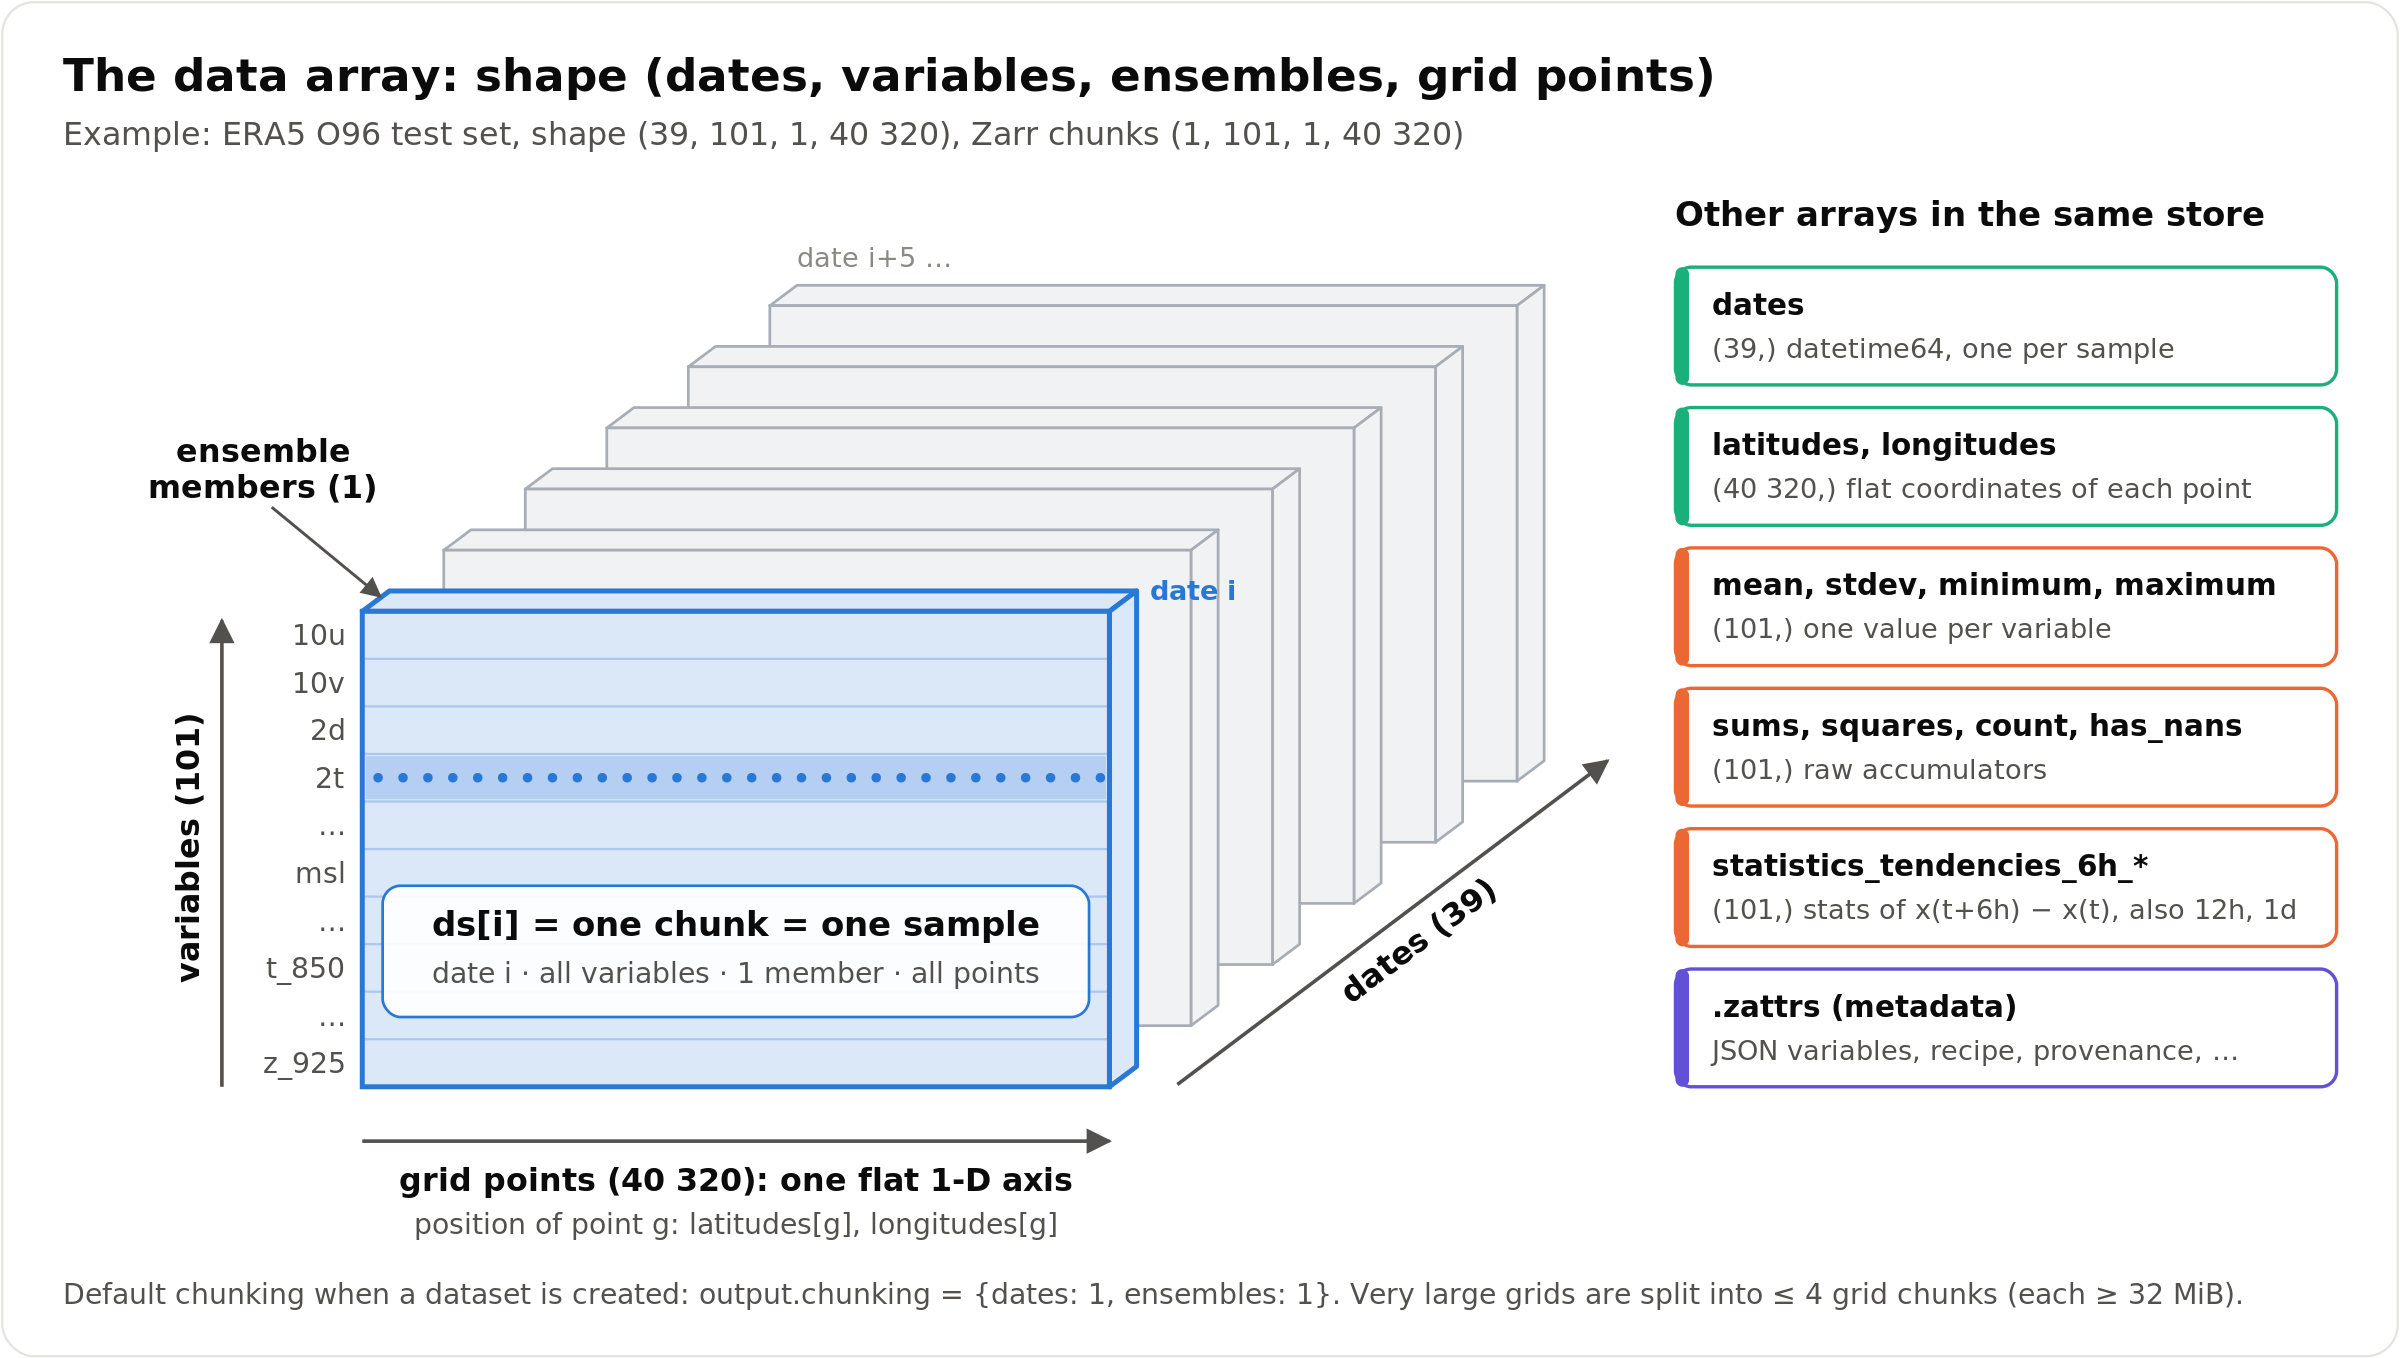

The heart of the store is **`data`**, a 4-D array **(dates, variables, ensemble members, grid points)**. Everything else describes it:
`dates`, `latitudes`/`longitudes`, per-variable statistics, and the attributes (`.zattrs`).

Look at the **chunk shape**: `(1, 101, 1, 40320)`. Each chunk holds **one date, all variables, one member, all grid points**.
The recipe's default is `output.chunking: {dates: 1, ensembles: 1}`, and you'll find exactly that in this dataset's recipe in Section 2.

> **Why one chunk per date?** A forecast model is trained on *states*: sample *i* is the full atmosphere at time *t* (and *t+Δt* for the target).
> With this layout, **one sample = one chunk = one file read**, which is the access pattern parallel filesystems (Lustre, GPFS) and object stores handle best: large, independent, contiguous reads, so many GPUs can each pull different dates at once.
> For very large grids the creator splits the grid into at most 4 chunks of at least 32 MiB each, so a sample is still only a handful of big reads.

In [3]:
data = z["data"]
chunk_mib = np.prod(data.chunks) * data.dtype.itemsize / 2**20
print(f"{data.nchunks} chunks of {data.chunks} → {chunk_mib:.1f} MiB each before compression ({data.compressor.cname})")
print("chunk files for date 0:", sorted(f for f in os.listdir(f"{O96}/data") if f.startswith("0.")))

ds = open_dataset(O96)   # the anemoi view of the same store
_ = ds[0]                # the very first read also initialises arrays and codecs (slow once)

t0 = time.perf_counter()
x = ds[25]               # one training sample: the full state at date index 25
print(f"\nds[25] → shape {x.shape} (variables, members, points): 1 chunk read, {1e3 * (time.perf_counter() - t0):.0f} ms")
print("(timings on a shared login node vary with filesystem caching; the number of chunks touched is what scales)")

39 chunks of (1, 101, 1, 40320) → 15.5 MiB each before compression (lz4)
chunk files for date 0: ['0.0.0.0']



ds[25] → shape (101, 1, 40320) (variables, members, points): 1 chunk read, 1104 ms
(timings on a shared login node vary with filesystem caching; the number of chunks touched is what scales)


### 1.2 The grid is flattened to one dimension

There is no `(lat, lon)` axis. Grid points live on **one flat axis**, and their positions are two 1-D arrays, `latitudes[g]` and `longitudes[g]`.

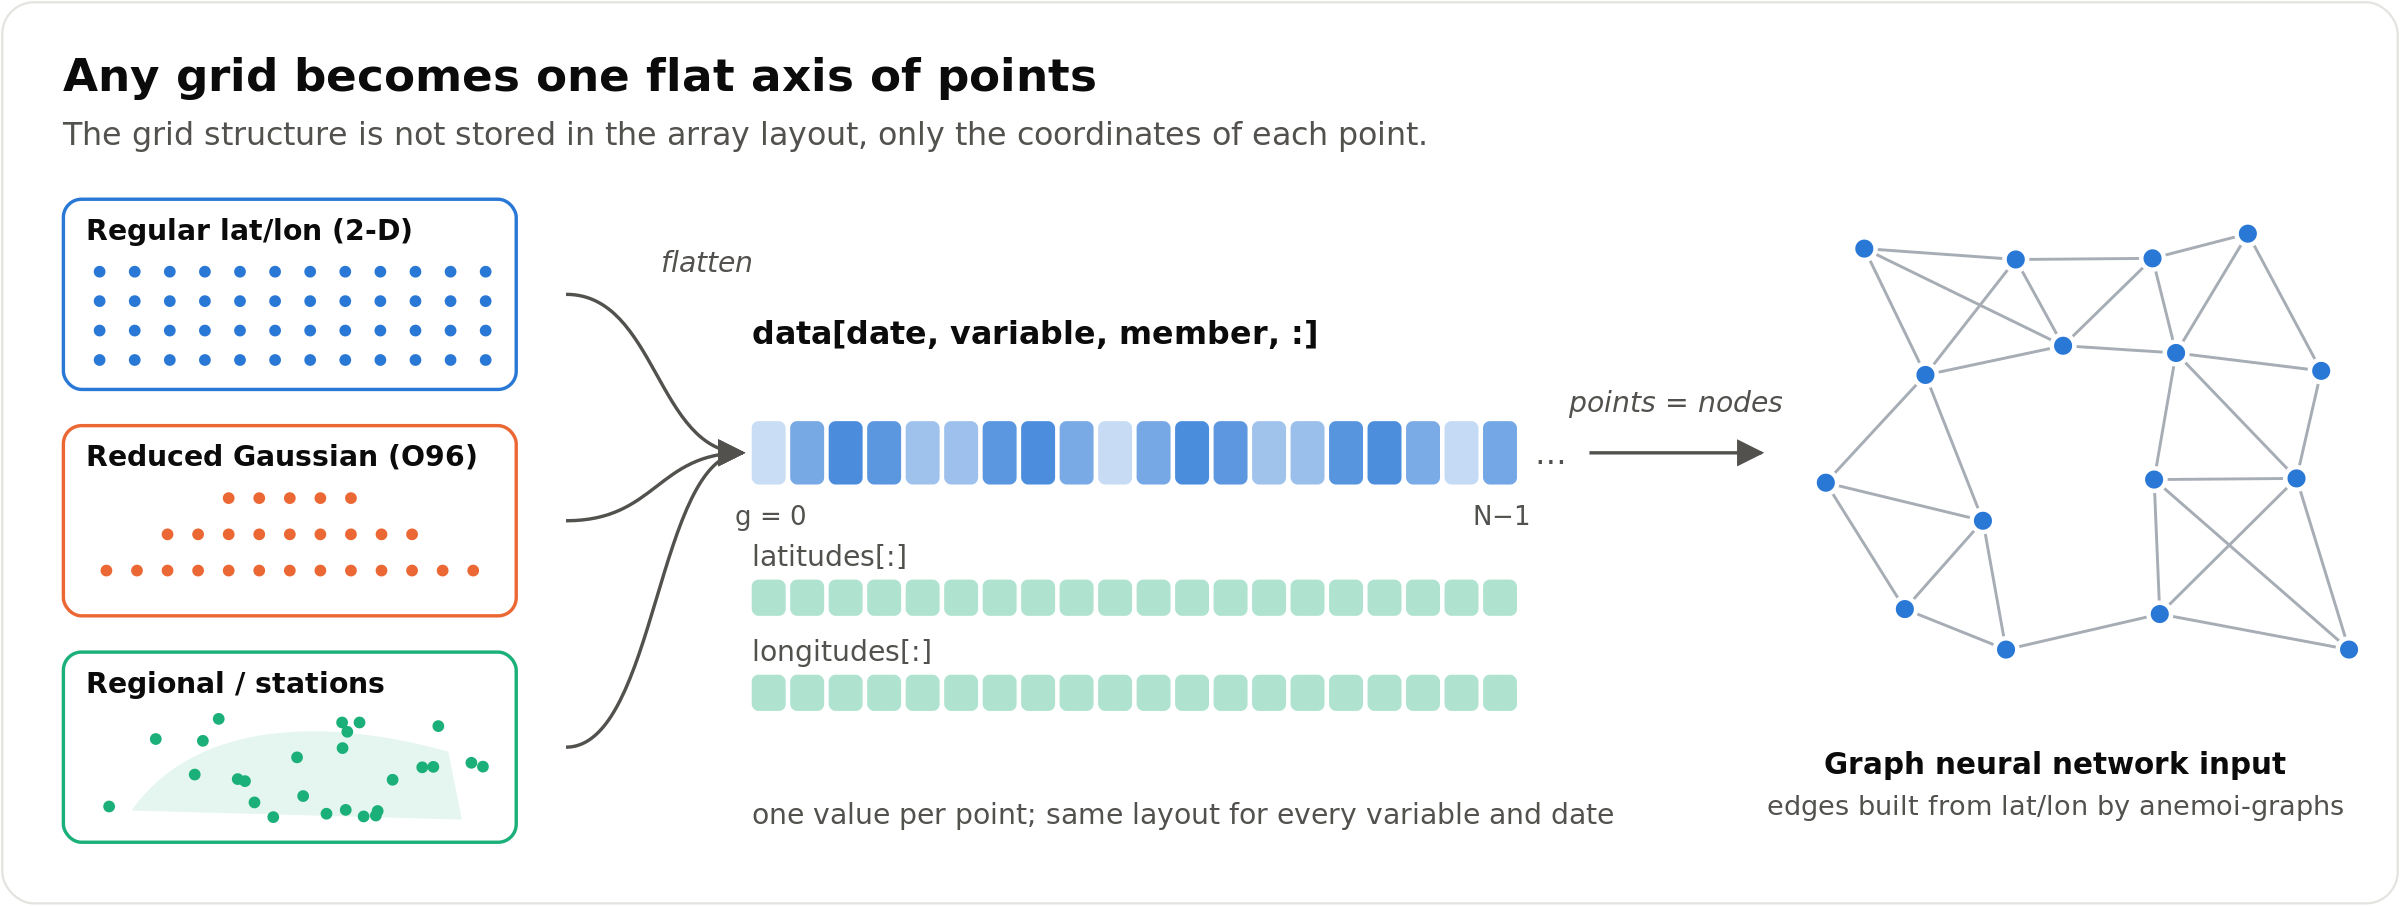

> **Why flatten?** Weather data increasingly lives on grids that are *not* rectangles: reduced Gaussian (ECMWF's octahedral O-grids), HEALPix, ICON triangles, limited-area projections, observation stations.
> With a flat axis the **same code handles all of them**, and you can concatenate several grids into one (see `cutout` below).
> It is also exactly what a **graph neural network** wants: every grid point becomes a node, and anemoi-graphs builds the edges from `latitudes`/`longitudes`.
> (`field_shape` remembers the original 2-D shape when there was one, e.g. `(360, 181)` for a regular 1° grid.)

Our O96 grid is a *reduced* Gaussian grid: each latitude ring has fewer points towards the poles, so grid spacing stays roughly uniform in km.

O96: 40,320 points on 192 latitude rings (20 points near the poles → 400 at the equator); field_shape = (40320,)


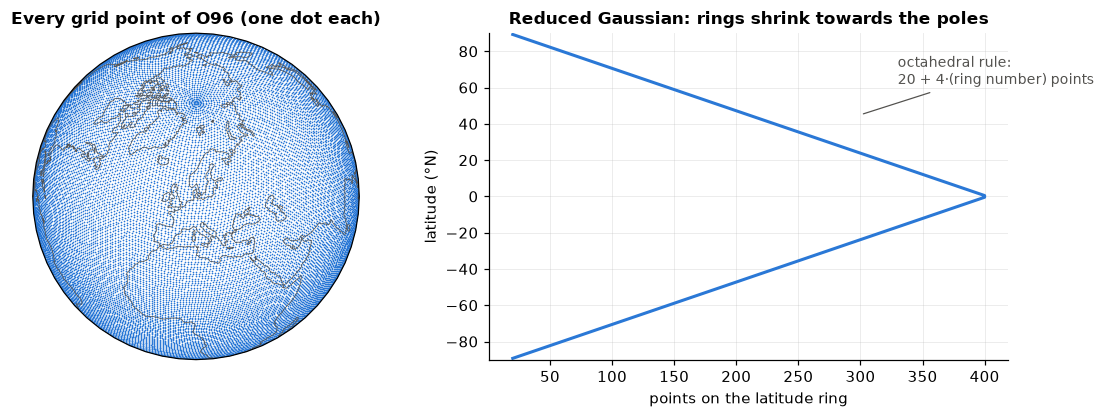

In [4]:
lats, lons = ds.latitudes, ds.longitudes
ring_lat, ring_n = np.unique(lats, return_counts=True)
print(f"{ds.resolution}: {len(lats):,} points on {len(ring_lat)} latitude rings "
      f"({ring_n.min()} points near the poles → {ring_n.max()} at the equator); field_shape = {ds.field_shape}")

fig = plt.figure(figsize=(11, 3.9))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.Orthographic(10, 55))
ax.set_global()
ax.scatter(lons, lats, s=1.2, color=C["blue"], linewidths=0, transform=ccrs.PlateCarree(), rasterized=True)
ax.coastlines(linewidth=0.5, color="#555555")
ax.set_title("Every grid point of O96 (one dot each)")

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(ring_n, ring_lat, color=C["blue"], lw=2)
ax2.set_xlabel("points on the latitude ring")
ax2.set_ylabel("latitude (°N)")
ax2.set_title("Reduced Gaussian: rings shrink towards the poles")
ax2.set_ylim(-90, 90)
ax2.annotate("octahedral rule:\n20 + 4·(ring number) points", xy=(300, 45), xytext=(330, 62),
             fontsize=9, color=C["ink"], arrowprops=dict(arrowstyle="-", color=C["ink"], lw=0.8))
fig.tight_layout()

Plotting needs no reshaping either. The `show_field` helper (in the setup cell) triangulates the flat points on the sphere and colours the triangles, so it works unchanged for the 1° lat/lon grid, a regional crop and the cutout later on.

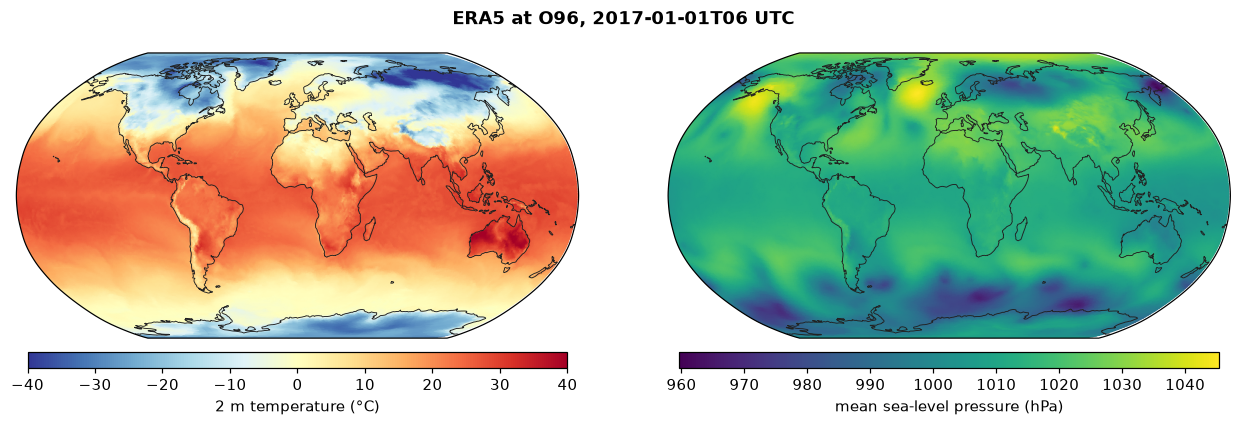

In [5]:
i = 0
fig, axs = plt.subplots(1, 2, figsize=(12, 3.9), subplot_kw={"projection": ccrs.Robinson()})
show_field(axs[0], lats, lons, ds[i, ds.name_to_index["2t"], 0] - 273.15,
           cmap="RdYlBu_r", label="2 m temperature (°C)", vmin=-40, vmax=40)
show_field(axs[1], lats, lons, ds[i, ds.name_to_index["msl"], 0] / 100,
           cmap="viridis", label="mean sea-level pressure (hPa)")
for ax in axs:
    ax.set_global()
fig.suptitle(f"ERA5 at O96, {np.datetime_as_string(ds.dates[i], unit='h')} UTC", fontweight="bold")
fig.tight_layout()

The flip side of the layout: a **time series at one point** has to touch *every* date chunk.
Let's extract one at FBK in Trento, finding the nearest grid point straight from the flat coordinates:

grid point 5066 at (46.29°N, 10.59°E): read 78 values from 39 chunks (606 MiB decompressed) in 1.93 s


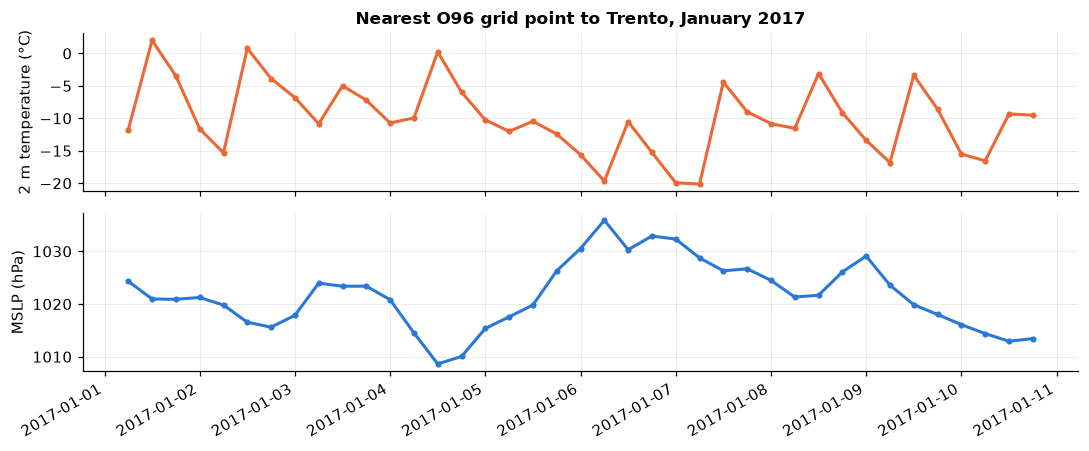

In [6]:
def nearest_point(ds, lat, lon):
    """Index of the grid point closest to (lat, lon): a great-circle distance on the flat arrays."""
    la1, lo1, la2, lo2 = map(np.radians, (lat, lon, ds.latitudes, ds.longitudes))
    d = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return int(np.argmin(d))

g = nearest_point(ds, 46.07, 11.12)   # Trento
iv = [ds.name_to_index[v] for v in ("2t", "msl")]
t0 = time.perf_counter()
ts = ds[:, iv, 0, g]                  # (dates, 2): 78 numbers…
dt = time.perf_counter() - t0
print(f"grid point {g} at ({lats[g]:.2f}°N, {lons[g]:.2f}°E): read {ts.size} values from "
      f"{len(ds)} chunks ({len(ds) * chunk_mib:.0f} MiB decompressed) in {dt:.2f} s")

fig, axs = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True)
axs[0].plot(ds.dates, ts[:, 0] - 273.15, color=C["orange"], lw=2, marker="o", ms=3)
axs[0].set_ylabel("2 m temperature (°C)")
axs[1].plot(ds.dates, ts[:, 1] / 100, color=C["blue"], lw=2, marker="o", ms=3)
axs[1].set_ylabel("MSLP (hPa)")
axs[0].set_title("Nearest O96 grid point to Trento, January 2017")
fig.autofmt_xdate()
fig.tight_layout()

That's fine for 39 dates, but over 40 years of hourly data it would mean reading the whole dataset. The layout is **optimised for the training access pattern (whole states)**, not for point time series.
That's a deliberate trade-off.

### 1.3 Precomputed statistics

Neural networks need inputs of order 1, so every variable is normalised, e.g. $\tilde{x} = (x-\mu)/\sigma$.
The statistics are computed **once, when the dataset is created**, and stored as arrays of one value per variable:
`mean`, `stdev`, `minimum`, `maximum` (plus the raw accumulators `sums`, `squares`, `count`, `has_nans`).

In [7]:
attrs = z.attrs
print("statistics period:", attrs["statistics_start_date"], "→", attrs["statistics_end_date"],
      f"(dataset: {attrs['start_date']} → {attrs['end_date']})")

st = ds.statistics   # dict of arrays, aligned with ds.variables
show = ["2t", "msl", "z_500", "q_850", "u_850", "tp"]
pd.DataFrame({k: st[k][[ds.name_to_index[v] for v in show]] for k in ("mean", "stdev", "minimum", "maximum")},
             index=show).style.format("{:.4g}")

statistics period: 2017-01-01T06:00:00 → 2017-01-08T18:00:00 (dataset: 2017-01-01T06:00:00 → 2017-01-10T18:00:00)


,mean,stdev,minimum,maximum
2t,286.8,16.01,218.4,318.8
msl,1.012e+05,1026,9.46e+04,1.056e+05
z_500,5.55e+04,2682,4.619e+04,5.826e+04
q_850,0.006013,0.004454,7.575e-07,0.01918
u_850,0.5961,7.997,-35.62,39.85
tp,0.0007543,0.002509,0,0.1437


> **Why precompute?** Normalising with statistics from a 40-year archive would otherwise need a full pass over terabytes *before every training run*.
> Storing them makes normalisation an O(1) lookup, and every experiment on that dataset uses *identical* normalisation.
>
> Notice the **statistics period** stops before the end of the data. By default the creator leaves out the last 20 % of dates (or the last 1–3 years for long datasets; see `default_statistics_dates` in `create/recipe/statistics.py`),
> so the normalisation never "sees" the data you'll later validate on.

Applying it to one sample:

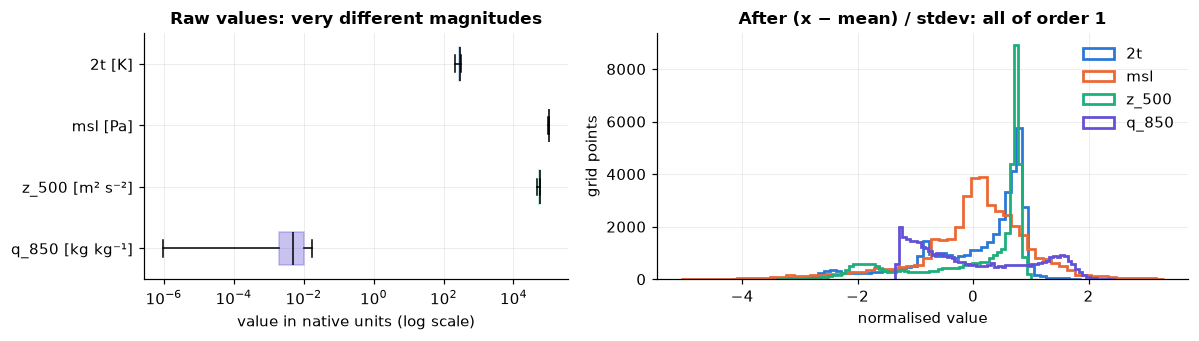

In [8]:
mean, std = st["mean"], st["stdev"]
xn = (ds[0] - mean[:, None, None]) / std[:, None, None]        # (variables, members, points)

names = ["2t", "msl", "z_500", "q_850"]
units = ["K", "Pa", "m² s⁻²", "kg kg⁻¹"]
cols = [C["blue"], C["orange"], C["aqua"], C["violet"]]
raw = [ds[0][ds.name_to_index[v], 0] for v in names]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.25]})
bp = axs[0].boxplot(raw, orientation="horizontal", whis=(0, 100), widths=0.55, patch_artist=True,
                    medianprops={"color": "k"}, tick_labels=[f"{v} [{u}]" for v, u in zip(names, units)])
for patch, col in zip(bp["boxes"], cols):
    patch.set(facecolor=col, alpha=0.35, edgecolor=col)
axs[0].set_xscale("log")
axs[0].invert_yaxis()
axs[0].set(title="Raw values: very different magnitudes", xlabel="value in native units (log scale)")
for v, col in zip(names, cols):
    axs[1].hist(xn[ds.name_to_index[v], 0], bins=60, histtype="step", lw=1.8, color=col, label=v)
axs[1].set(title="After (x − mean) / stdev: all of order 1", xlabel="normalised value", ylabel="grid points")
axs[1].legend(frameon=False)
fig.tight_layout()

This dataset also stores **tendency statistics**: stats of $x(t+\Delta t) - x(t)$ for Δt = 6 h, 12 h and 1 day.
They're used when a model predicts the *increment* to the next state rather than the state itself. Increments are much smaller than the fields.

In [9]:
tend6 = ds.statistics_tendencies("6h")
pd.DataFrame({"stdev of field": st["stdev"][[ds.name_to_index[v] for v in show]],
              "stdev of 6 h tendency": tend6["stdev"][[ds.name_to_index[v] for v in show]]},
             index=show).style.format("{:.3g}")

,stdev of field,stdev of 6 h tendency
2t,16,2.64
msl,1.03e+03,261
z_500,2.68e+03,236
q_850,0.00445,0.0014
u_850,8,2.83
tp,0.00251,0.00251


### 1.4 Missing dates

Real archives have holes (a missing analysis, a corrupt file). anemoi-datasets keeps the time axis **regular** and records holes in the `missing_dates` attribute instead of dropping them, so index arithmetic like "*i* + 1 = 6 h later" stays valid.
Our sample has none (`ds.missing` is an empty set), so we'll fake one with the debugging option `set_missing_dates`:

In [10]:
print("real dataset, missing:", ds.missing)

holey = open_dataset(O96, set_missing_dates=["2017-01-03T00:00:00"])
print("with a fake hole, missing indices:", holey.missing)
try:
    holey[7]
except Exception as e:
    print(f"holey[7] → {type(e).__name__}: {e}")

filled = open_dataset(holey, fill_missing_dates="closest")   # or "interpolate", "nans"
print("after fill_missing_dates='closest':", filled[7].shape, "(no error)")

real dataset, missing: set()


with a fake hole, missing indices: {7}
holey[7] → MissingDateError: Date 2017-01-03T00:00:00 is missing (index=7)
after fill_missing_dates='closest': (101, 1, 40320) (no error)


The training data loader uses `ds.missing` to skip every sample window that would touch a hole.

---
### ✏️ Try it 1 (≈ 2 min)

Find the index of **2017-01-05 12:00 UTC** in `ds.dates`, read that single sample, and normalise **`2t`** with the stored statistics.
What fraction of grid points is more than 2 standard deviations from the mean?

In [11]:
# your code here
...

Ellipsis

<details><summary><b>Show solution</b></summary>

```python
i = int(np.where(ds.dates == np.datetime64("2017-01-05T12:00"))[0][0])
k = ds.name_to_index["2t"]
t2n = (ds[i, k, 0] - ds.statistics["mean"][k]) / ds.statistics["stdev"][k]
print(i, f"{np.mean(np.abs(t2n) > 2):.1%}")      # → 17, about 7 % of points
```
`2t` is far from Gaussian (polar vs tropical air), so the tails don't follow the 4.6 % you'd expect from a normal distribution.
</details>

## 2 · Metadata: the dataset describes itself

### 2.1 From the command line

`anemoi-datasets inspect` gives the summary you'd check first. (The CLI loads all its plugins from Lustre, so allow it ~30–40 s.)

In [12]:
!anemoi-datasets inspect {O96} 2>/dev/null | sed 's/\x1b\[[0-9;]*m//g' | awk 'NR <= 30'

📦 Path          : /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr
🔢 Format version: 0.30.0

📅 Date      start: 2017-01-01 06:00
📅 Date      end  : 2017-01-10 18:00
⏰ Frequency  : 6h
🚫 Missing    : 0
🌎 Resolution : O96
🌎 Field shape: [40320]

📅 Data start : None
📅 Data end   : None

📐 Shape      : 39 × 101 × 1 × 40,320 (605.9 MiB)
💽 Size       : 361.4 MiB (361.4 MiB)
📁 Files      : 157


                                   Statistics                                   
┏━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┓
┃ Index ┃ Variable       ┃       Min ┃      Max ┃      Mean ┃    Stdev ┃ Units ┃
┡━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━┩
│     0 │ 10u            │     -21.7 │     24.6 │    -0.681 │     5.16 │ -     │
│     1 │ 10v            │     -25.9 │     21.6 │    -0.254 │     4.39 │ -     │
│     2 │ 2d             │       215 │      301 │       282 │   

### 2.2 From Python

All of this, and more, lives in the Zarr attributes:

In [13]:
print(sorted(attrs.keys()))
print()
for k in ["description", "resolution", "frequency", "field_shape", "flatten_grid", "licence", "attribution",
          "constant_fields", "variables_with_nans", "missing_dates"]:
    print(f"{k:20s}: {attrs[k]}")

['allow_nans', 'attribution', 'constant_fields', 'data_request', 'description', 'end_date', 'ensemble_dimension', 'field_shape', 'flatten_grid', 'frequency', 'history', 'latest_write_timestamp', 'licence', 'missing_dates', 'order_by', 'proj_string', 'provenance_load', 'recipe', 'remapping', 'resolution', 'start_date', 'statistics_end_date', 'statistics_start_date', 'total_number_of_files', 'total_size', 'uuid', 'variables', 'variables_metadata', 'variables_with_nans', 'version']

description         : Subset of aifs-ea-an-oper-0001-mars-o96-1979-2023-6h-v8, for purposes of integration testing Data from 2017, resolution O96. From ERA5 data, deterministic. 
resolution          : O96
frequency           : 6h
field_shape         : [40320]
flatten_grid        : True
licence             : CC-BY-4.0
attribution         : ECMWF
constant_fields     : ['cos_latitude', 'cos_longitude', 'lsm', 'sdor', 'sin_latitude', 'sin_longitude', 'slor', 'z']
variables_with_nans : []
missing_dates       : []


**`variables_metadata`** records, for each variable, *where it came from*: here the exact MARS request (ECMWF's archive).
Downstream tools use it, e.g. to tell pressure-level from surface fields, or accumulations from instantaneous values.

In [14]:
for v in ["2t", "t_850", "tp"]:
    print(f"{v:6s}", ds.variables_metadata[v])

2t     {'mars': {'class': 'ea', 'date': 20170101, 'domain': 'g', 'expver': '0001', 'levtype': 'sfc', 'param': '2t', 'step': 0, 'stream': 'oper', 'time': 600, 'type': 'an'}}
t_850  {'mars': {'class': 'ea', 'date': 20170101, 'domain': 'g', 'expver': '0001', 'levelist': 850, 'levtype': 'pl', 'param': 't', 'step': 0, 'stream': 'oper', 'time': 600, 'type': 'an'}}
tp     {'mars': {'class': 'ea', 'date': 20161231, 'domain': 'g', 'expver': '0001', 'levtype': 'sfc', 'param': 'tp', 'step': 12, 'stream': 'oper', 'time': 1800, 'type': 'fc'}, 'period': ['6h', '12h'], 'process': 'accumulation'}


The **recipe**, the YAML file that built the dataset, is stored inside it. Here's an excerpt (the full one also requests ~78 pressure-level fields, accumulations and computed forcings):

In [15]:
recipe = attrs["recipe"]
excerpt = {"dates": recipe["dates"],
           "input": {"join": [recipe["input"]["join"][0], "… (pressure levels, accumulations, forcings)"]},
           "output": {k: recipe["output"][k] for k in ("chunking", "dtype", "flatten_grid")}}
print(yaml.safe_dump(excerpt, sort_keys=False, default_flow_style=None, width=110))

prov = attrs["provenance_load"]
print("built with python", prov["python"], "and",
      {m: prov["module_versions"][m] for m in ("anemoi.datasets", "anemoi.transform", "earthkit.data")
       if m in prov["module_versions"]})

dates: {end: '2017-01-10T18:00:00', frequency: 6h, group_by: monthly, start: '2017-01-01T06:00:00'}
input:
  join:
  - mars:
      class: ea
      expver: '0001'
      grid: o96
      levtype: sfc
      param: [10u, 10v, 2d, 2t, lsm, msl, sdor, skt, slor, sp, tcw, z]
  - "\u2026 (pressure levels, accumulations, forcings)"
output:
  chunking: {dates: 1, ensembles: 1}
  dtype: float32
  flatten_grid: true

built with python 3.11.11 and {'anemoi.datasets': '0.5.17.dev21+g5a0f5ab', 'anemoi.transform': '0.1.4.dev5+g3e669c0', 'earthkit.data': '0.13.4'}


> **Why store the recipe and provenance?** **Reproducibility.** Months later, anyone (or any checkpoint) can see *exactly* which source data, grid, time range and software versions produced the numbers a model was trained on, and can rebuild it.
> When you open a dataset, `ds.metadata()` additionally records **every view you applied** (next section). anemoi-training saves this into each model checkpoint.

## 3 · `open_dataset`: lazy views that compose

`open_dataset(path, **options)` returns a *view*. Each option wraps the dataset in another lazy object that behaves exactly like a dataset (`shape`, `dates`, `variables`, `statistics`, `ds[i]`, …).
**Nothing is read or copied** until you index the result.

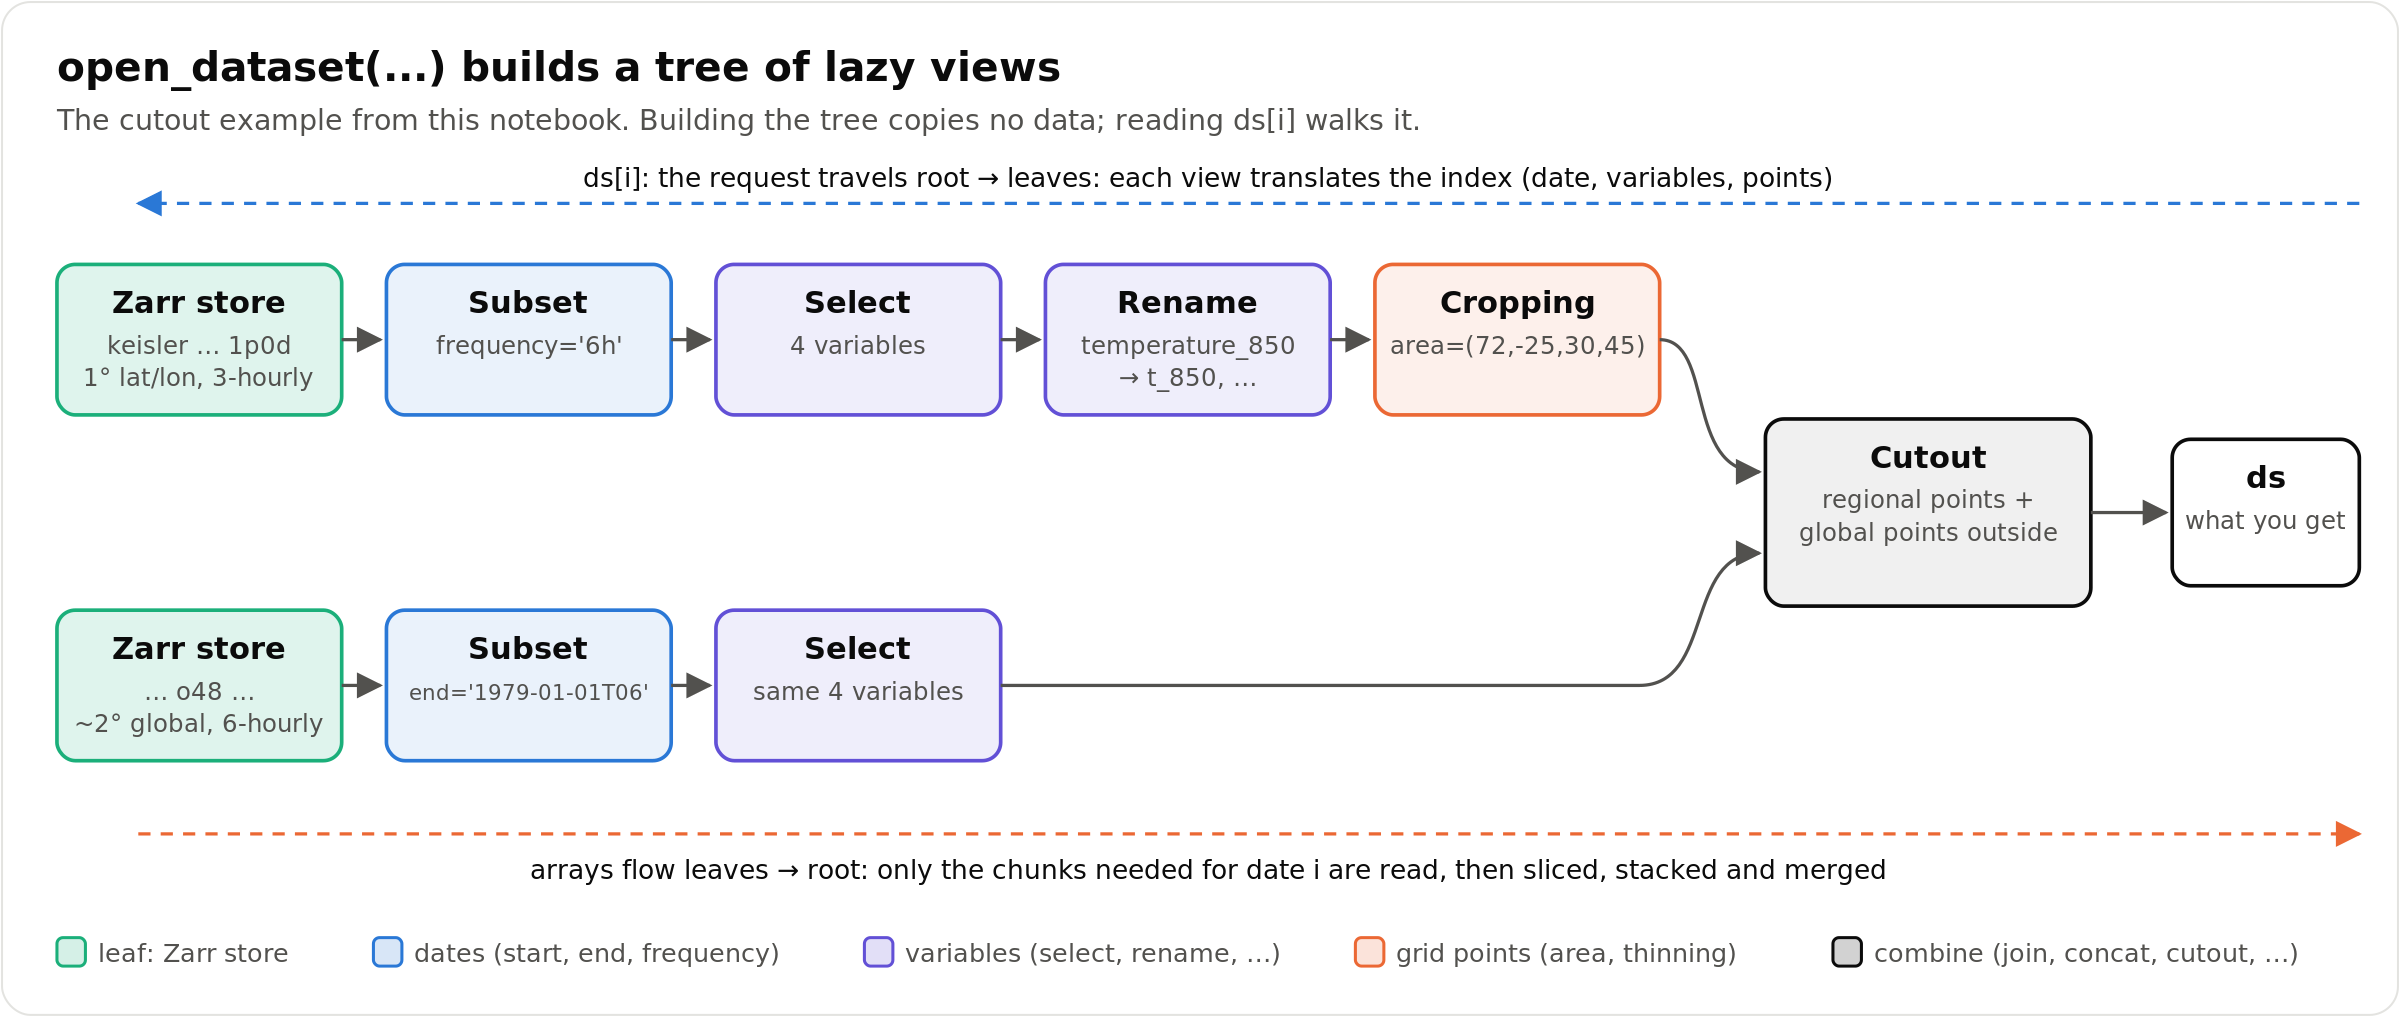

### 3.1 Dates: `start`, `end`, `frequency`

In [16]:
t0 = time.perf_counter()
v = open_dataset(O96, start="2017-01-03", end="2017-01-06", frequency="12h")
print(f"built in {1e3 * (time.perf_counter() - t0):.1f} ms → shape {v.shape}")
print(v.dates)

built in 670.9 ms → shape (8, 101, 1, 40320)
['2017-01-03T00:00:00' '2017-01-03T12:00:00' '2017-01-04T00:00:00'
 '2017-01-04T12:00:00' '2017-01-05T00:00:00' '2017-01-05T12:00:00'
 '2017-01-06T00:00:00' '2017-01-06T12:00:00']


### 3.2 Variables: `select`, `drop`, `reorder`, `rename`

`select` with a **list** also sets the order; with a **set** it keeps the stored order. Statistics follow the selection automatically.

In [17]:
v = open_dataset(O96, select=["msl", "2t", "10u", "10v"])
print("select :", v.variables, "| mean:", [f"{m:.1f}" for m in v.statistics["mean"]])
print("drop   :", len(open_dataset(O96, drop=["tp", "cp"]).variables), "variables left")
print("reorder:", open_dataset(v, reorder=["2t", "msl", "10u", "10v"]).variables)
print("rename :", open_dataset(v, rename={"2t": "t2m", "msl": "mslp"}).variables)

select : ['msl', '2t', '10u', '10v'] | mean: ['101150.7', '286.8', '-0.7', '-0.3']
drop   : 99 variables left
reorder: ['2t', 'msl', '10u', '10v']
rename : ['mslp', 't2m', '10u', '10v']


Note that `open_dataset(v, …)` accepts an **already-opened view** and wraps it further.

### 3.3 Grid points: `area` and `thinning`

`area=(north, west, south, east)` keeps only the points inside the box. It works on any grid, because it is just a mask on the flat axis:

grid points: global 40,320 → europe 1,622 → italy 133


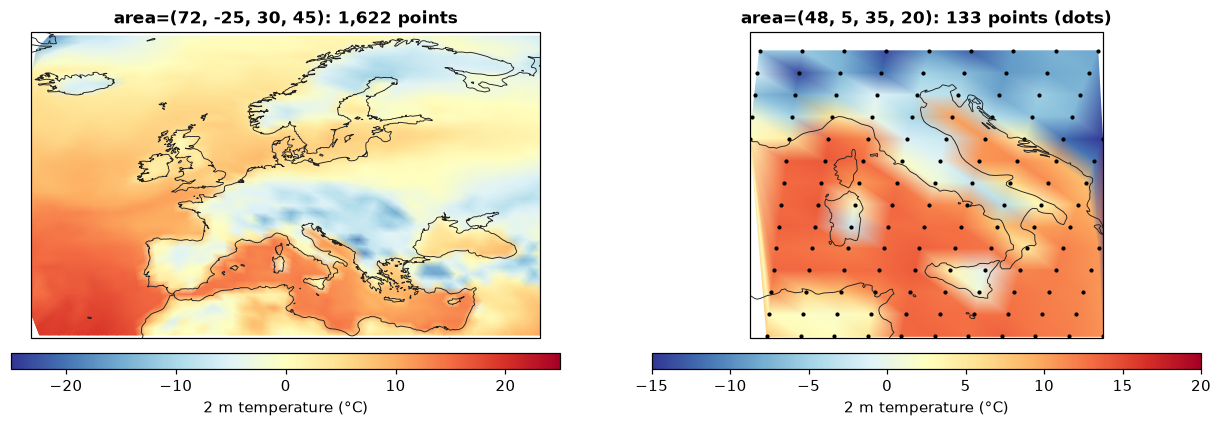

In [18]:
europe = open_dataset(O96, area=(72, -25, 30, 45))
italy = open_dataset(O96, area=(48, 5, 35, 20), select=["2t"])
print(f"grid points: global {ds.shape[-1]:,} → europe {europe.shape[-1]:,} → italy {italy.shape[-1]:,}")

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
k = europe.name_to_index["2t"]
show_field(ax, europe.latitudes, europe.longitudes, europe[0, k, 0] - 273.15,
           cmap="RdYlBu_r", vmin=-25, vmax=25, label="2 m temperature (°C)")
ax.set_extent([-25, 45, 30, 72], crs=ccrs.PlateCarree())
ax.set_title(f"area=(72, -25, 30, 45): {europe.shape[-1]:,} points")

ax = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
show_field(ax, italy.latitudes, italy.longitudes, italy[0, 0, 0] - 273.15,
           cmap="RdYlBu_r", vmin=-15, vmax=20, label="2 m temperature (°C)")
ax.scatter(lon180(italy.longitudes), italy.latitudes, s=3, color="k", transform=ccrs.PlateCarree())
ax.set_extent([5, 20, 35, 48], crs=ccrs.PlateCarree())
ax.set_title(f"area=(48, 5, 35, 20): {italy.shape[-1]} points (dots)")
fig.tight_layout()

`thinning=N` keeps every N-th point in each direction. It is a quick way to get a coarse version for debugging.
**Gotcha (this version):** it needs a 2-D `field_shape`, i.e. a regular lat/lon grid. On our reduced-Gaussian O96 it raises an error, so we use the 1° WeatherBench 2 dataset:

O96 + thinning → Thinning only works latitude/longitude fields
WB2 field_shape (360, 181): 65,160 points → thinned: 4,140


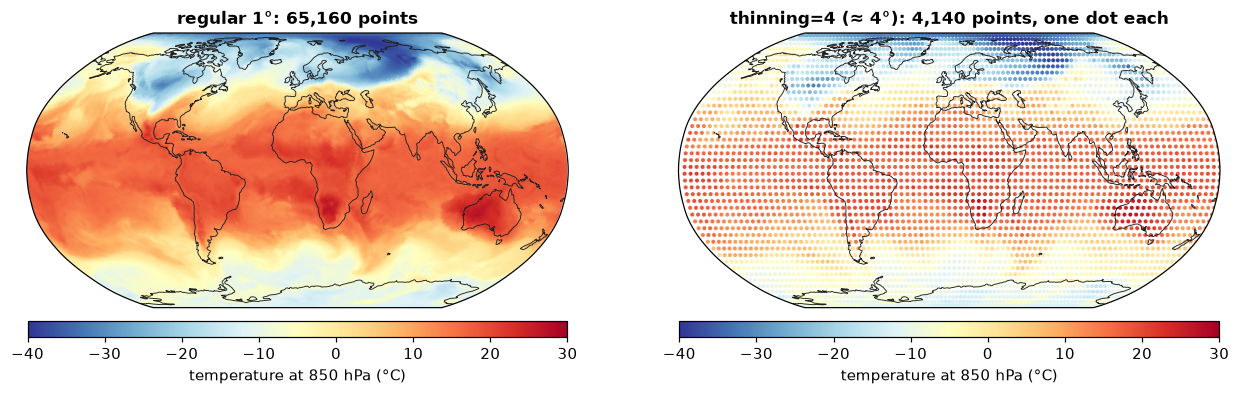

In [19]:
try:
    open_dataset(O96, thinning=4)
except ValueError as e:
    print("O96 + thinning →", e)

wb2 = open_dataset(WB2, select=["temperature_850"])
thin = open_dataset(wb2, thinning=4)
print(f"WB2 field_shape {wb2.field_shape}: {wb2.shape[-1]:,} points → thinned: {thin.shape[-1]:,}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), subplot_kw={"projection": ccrs.Robinson()})
kw = dict(cmap="RdYlBu_r", vmin=-40, vmax=30)
show_field(axs[0], wb2.latitudes, wb2.longitudes, wb2[0, 0, 0] - 273.15, label="temperature at 850 hPa (°C)", **kw)
axs[0].set_title(f"regular 1°: {wb2.shape[-1]:,} points")
im = axs[1].scatter(thin.longitudes, thin.latitudes, c=thin[0, 0, 0] - 273.15, s=7, linewidths=0,
                    transform=ccrs.PlateCarree(), rasterized=True, **kw)
axs[1].coastlines(linewidth=0.6, color="#222222")
plt.colorbar(im, ax=axs[1], orientation="horizontal", pad=0.04, shrink=0.85, aspect=35,
             label="temperature at 850 hPa (°C)")
axs[1].set_title(f"thinning=4 (≈ 4°): {thin.shape[-1]:,} points, one dot each")
for ax in axs:
    ax.set_global()
fig.tight_layout()

### 3.4 Statistics from elsewhere: `statistics=`

By default a view keeps the statistics of its (first) source dataset. `statistics=other` swaps them in from another dataset with matching variables.
That's what you want when **fine-tuning** a model on new data: keep the normalisation it was trained with.

In [20]:
mine = open_dataset(O96, select=["2t", "msl"])
other = open_dataset(O96, select=["2t", "msl"], statistics=O48)
print("own stats (O96, Jan 2017):", np.round(mine.statistics["mean"], 2))
print("from O48  (Jan 1979)     :", np.round(other.statistics["mean"], 2))

own stats (O96, Jan 2017): [   286.76 101150.66]
from O48  (Jan 1979)     : [   285.35 101121.66]


### 3.5 Combining datasets: `join`, `concat`, `ensemble`

Combinators take a **list** of datasets (paths, views or dicts) and check that they're compatible (same grid, dates, variables… as appropriate).
These toy datasets sit on a 20° grid (162 points), so everything is instant:

| Combinator | Glues along | Requires the same |
|---|---|---|
| `join` | variables | dates, grid |
| `concat` | dates | variables, grid (dates must follow on) |
| `ensemble` | members | dates, variables, grid |

In [21]:
j = open_dataset(join=[T20_SFC, T20_PL])
print("join    :", open_dataset(T20_SFC).shape, "+", open_dataset(T20_PL).shape, "→", j.shape)
print("          variables:", j.variables)

c = open_dataset(concat=[T20_2016, T20_2017])
print("concat  :", c.shape, "dates", c.dates[0], "→", c.dates[-1])

e = open_dataset(ensemble=[T20_2017, T20_ENS])   # deterministic analysis (1) + 3 EDA members
print("ensemble:", e.shape, "← members on axis 2;  number=[1, 3] →", open_dataset(e, number=[1, 3]).shape)
print()
print(j.tree())

join    : (124, 4, 1, 162) + (124, 4, 1, 162) → (124, 8, 1, 162)
          variables: ['2t', 'lsm', 'msl', 'z', 't_500', 't_850', 'z_500', 'z_850']


concat  : (248, 12, 1, 162) dates 2016-12-01T00:00:00 → 2017-01-31T18:00:00


ensemble: (124, 12, 4, 162) ← members on axis 2;  number=[1, 3] → (124, 12, 2, 162)

Join
  GriddedZarr
    path: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-20p0-2017-2017-6h-v1-sfc.zarr
  GriddedZarr
    path: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-20p0-2017-2017-6h-v1-pl.zarr


### 3.6 Putting it together: a limited-area cutout

`cutout=[regional, global]` keeps **all** regional points and only those global points **outside** the region, then concatenates them on the flat grid axis.
This is how Anemoi trains *stretched-grid* / limited-area models: high resolution where you care, coarse boundary conditions elsewhere.

Here the "regional" input is the 1° WB2 data over Europe, and the "global" input is ERA5 at O48 (≈ 2°).
They come from different producers with **different variable names and time steps**, but views fix that on the fly:
- WB2 is 3-hourly → `frequency="6h"`; O48 has 10 days → `end=` the 2 dates both share;
- WB2 says `temperature_850`, O48 says `t_850` → `select` + `rename`.

The whole experiment is written as **plain dictionaries**, exactly as it would appear in a YAML config:

In [22]:
rename = {"temperature_850": "t_850", "geopotential_500": "z_500",
          "u_component_of_wind_850": "u_850", "v_component_of_wind_850": "v_850"}
config = {
    "dataset": {
        "cutout": [
            {"dataset": WB2, "frequency": "6h", "select": list(rename), "rename": rename,
             "area": [72, -25, 30, 45]},
            {"dataset": O48, "end": "1979-01-01T06:00:00", "select": list(rename.values())},
        ],
    },
}
t0 = time.perf_counter()
lam = open_dataset(config)
print(f"built in {time.perf_counter() - t0:.1f} s (cutout computes a point mask once)")
print("shape", lam.shape, "| grids (regional, global):", tuple(int(n) for n in lam.grids), "| variables", lam.variables)
print()
print(lam.tree())

built in 1.8 s (cutout computes a point mask once)
shape (2, 4, 1, 13442) | grids (regional, global): (2982, 10460) | variables ['t_850', 'z_500', 'u_850', 'v_850']

Cutout
  Cropping
    area: 72, -25, 30, 45
    Rename
      rename: {'temperature_850': 't_850', 'geopotential_500': 'z_500', 'u_component_of_wind_850': 'u_850', 'v_component_of_wind_850': 'v_850'}
      Select
        select: temperature_850, geopotential_500,...
        Subset
          frequency: 6h
          GriddedZarr
            path: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/keisler-era5-gs-weatherbench2-1p0d-1979-1979-3h-v0.zarr
  Select
    select: t_850, z_500, u_850, v_850
    Subset
      end: 1979-01-01T06:00:00
      GriddedZarr
        path: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o48-1979-19-6h-v6-testset.zarr


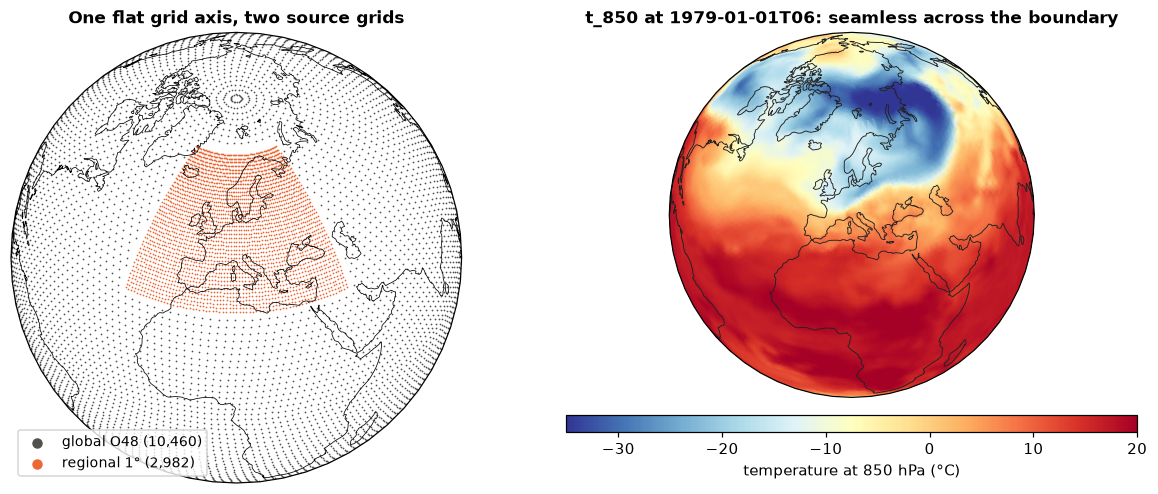

In [23]:
n_reg = int(lam.grids[0])
is_reg = np.arange(lam.shape[-1]) < n_reg
k = lam.name_to_index["t_850"]

fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.Orthographic(10, 45))
ax.set_global()
ax.scatter(lam.longitudes[~is_reg], lam.latitudes[~is_reg], s=1.3, color=C["ink"], linewidths=0,
           transform=ccrs.PlateCarree(), label=f"global O48 ({(~is_reg).sum():,})", rasterized=True)
ax.scatter(lam.longitudes[is_reg], lam.latitudes[is_reg], s=1.3, color=C["orange"], linewidths=0,
           transform=ccrs.PlateCarree(), label=f"regional 1° ({n_reg:,})", rasterized=True)
ax.coastlines(linewidth=0.5)
ax.legend(loc="lower left", markerscale=6, frameon=True, fontsize=9)
ax.set_title("One flat grid axis, two source grids")

ax = fig.add_subplot(1, 2, 2, projection=ccrs.Orthographic(10, 45))
ax.set_global()
show_field(ax, lam.latitudes, lam.longitudes, lam[1, k, 0] - 273.15, cmap="RdYlBu_r",
           vmin=-35, vmax=20, label="temperature at 850 hPa (°C)")
ax.set_title(f"t_850 at {np.datetime_as_string(lam.dates[1], unit='h')}: seamless across the boundary")
fig.tight_layout()

Two things to notice:

* **No new dataset was written.** Change the box, the variables or the period and you have a new experiment in milliseconds. Without views, each variant would be another multi-TB copy to create, store and keep in sync.
* The dictionary *is* the experiment. anemoi-training passes each `dataloader.<split>.datasets.<name>.dataset_config` entry of its Hydra config **straight to `open_dataset`**, adding the split's `start`/`end`.
  Training, validation and test sets are themselves just date views of one dataset. And `lam.metadata()` records the whole tree, so the checkpoint knows how its data was assembled:

In [24]:
training_cfg = {"dataloader": {"training": {"datasets": {"data": {"dataset_config": config, "start": None, "end": "1979-01-01T00"}}}}}
print(yaml.safe_dump(training_cfg, sort_keys=False, width=120).replace(DATA_DIR, "${DATA_DIR}"))
print("recorded in lam.metadata():", list(lam.metadata().keys()))

dataloader:
  training:
    datasets:
      data:
        dataset_config:
          dataset:
            cutout:
            - dataset: ${DATA_DIR}/anemoi/keisler-era5-gs-weatherbench2-1p0d-1979-1979-3h-v0.zarr
              frequency: 6h
              select:
              - temperature_850
              - geopotential_500
              - u_component_of_wind_850
              - v_component_of_wind_850
              rename:
                temperature_850: t_850
                geopotential_500: z_500
                u_component_of_wind_850: u_850
                v_component_of_wind_850: v_850
              area:
              - 72
              - -25
              - 30
              - 45
            - dataset: ${DATA_DIR}/anemoi/aifs-ea-an-oper-0001-mars-o48-1979-19-6h-v6-testset.zarr
              end: '1979-01-01T06:00:00'
              select:
              - t_850
              - z_500
              - u_850
              - v_850
        start: null
        end: 1979-01-01T00

reco

### ✏️ Try it 2 (≈ 2 min)

Build a view for an **Italy-focused** experiment from `O96`:
12-hourly, from 2017-01-02 to 2017-01-08, only `2t`, `msl`, `tp`, `z_500`, with `2t` renamed to `t2m`, cropped to `area=(48, 5, 35, 20)`.
Print its `shape` and `tree()`. In what order were the options applied?

In [25]:
# your code here
...

Ellipsis

<details><summary><b>Show solution</b></summary>

```python
it = open_dataset(O96, start="2017-01-02", end="2017-01-08", frequency="12h",
                  select=["2t", "msl", "tp", "z_500"], rename={"2t": "t2m"}, area=(48, 5, 35, 20))
print(it.shape)        # (14, 4, 1, 133): 2017-01-02T00 … 2017-01-08T12, every 12 h
print(it.tree())
```
Whatever order you write the keywords in, `open_dataset` applies them in a fixed order: dates (`Subset`) first, then `Select`, `Rename`, and the grid `Cropping` outermost.
</details>

### ✏️ Try it 3 (≈ 1 min)

Write the same view as **one dictionary** (as it would appear in a YAML config) and check that `open_dataset(that_dict)` gives *identical* data for the first sample (`np.array_equal`).

In [26]:
# your code here
...

Ellipsis

<details><summary><b>Show solution</b></summary>

```python
cfg = {"dataset": O96, "start": "2017-01-02", "end": "2017-01-08", "frequency": "12h",
       "select": ["2t", "msl", "tp", "z_500"], "rename": {"2t": "t2m"}, "area": [48, 5, 35, 20]}
it2 = open_dataset(cfg)
print(np.array_equal(it[0], it2[0]), it2.variables)   # True ['t2m', 'msl', 'tp', 'z_500']
```
</details>

## 4 · Wrap-up: what you just saw and why it's built that way

| Design choice | What it buys you |
|---|---|
| `data` is **(dates, variables, members, grid points)**, chunked **one date × all variables** | one training sample = one big read; scales on parallel filesystems (the cost: point time series are slow) |
| Grid **flattened to 1-D** + `latitudes`/`longitudes` | any mesh (reduced Gaussian, HEALPix, LAM, stations) with the same code; maps directly to GNN nodes; grids can be concatenated (`cutout`, `grids`) |
| **Precomputed statistics** (incl. tendencies), on a period that excludes the final dates | normalisation without a data pass; identical across experiments; no leakage from validation years |
| **Regular time axis** + `missing_dates` | index arithmetic stays valid; the loader skips holes safely |
| **Recipe + provenance** in the attributes | every number is traceable and the dataset can be rebuilt |
| **`open_dataset` lazy views** | an experiment is a config entry, not a new multi-TB copy; the view tree is saved in checkpoints |

**Next:** notebook 02 turns the flat `latitudes`/`longitudes` into a graph. In notebook 04 these datasets feed **anemoi-training**: look for the `dataloader.*.datasets.*.dataset_config` entries, which are exactly the dictionaries you just wrote.

*Further reading:* anemoi-datasets docs, "Using datasets" → *How it works*, *Combining datasets*, *Selecting grid points* ([anemoi-datasets.readthedocs.io](https://anemoi-datasets.readthedocs.io)).